# 02 · Huấn luyện model

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / 'pyproject.toml').exists():
    ROOT = ROOT.parent
if not (ROOT / 'pyproject.toml').exists():
    raise FileNotFoundError('Mở notebook từ thư mục dự án hoặc notebooks/.')
sys.path.insert(0, str(ROOT))
from scripts import final_study as study
from IPython.display import display
study.style()

In [2]:
bars, samples, cfg = study.load_data()
display(cfg.to_dict())
print('Ridge alpha=10; XGBoost 120 rounds; TCN 6 epochs cố định/fit, seed=42.')
print('Không chọn epoch hoặc siêu tham số theo outer validation.')

Ridge alpha=10; XGBoost 120 rounds; TCN 6 epochs cố định/fit, seed=42.
Không chọn epoch hoặc siêu tham số theo outer validation.


{'symbols': ('BTCUSDT', 'ETHUSDT'),
 'interval': '1h',
 'start_month': '2023-01',
 'end_month': '2026-11',
 'horizon': 4,
 'execution_lag_bars': 1,
 'fee_bps': 10.0,
 'slippage_bps': 5.0,
 'position_fraction': 0.1,
 'drawdown_halt': 0.1,
 'test_fraction': 0.2,
 'walk_forward_folds': 3,
 'minimum_trades': 20,
 'seed': 42,
 'threads': 4,
 'lookback': 48}

6 thử nghiệm inner split trước outer validation; không thay cấu hình baseline đã cố định.


,model,parameter,rows,mae,mse,mse_ratio_to_zero,directional_accuracy
0,ridge,1.0,1346,0.005573,0.000068,1.008887,0.471768
1,ridge,10.0,1346,0.005574,0.000068,1.008897,0.476226
2,ridge,100.0,1346,0.005574,0.000068,1.008858,0.478455
3,xgboost_d3,2.0,1346,0.005524,0.000067,1.002783,0.520059
4,xgboost_d3,3.0,1346,0.005535,0.000067,1.006023,0.513373
5,xgboost_d3,5.0,1346,0.005549,0.000068,1.014335,0.500743


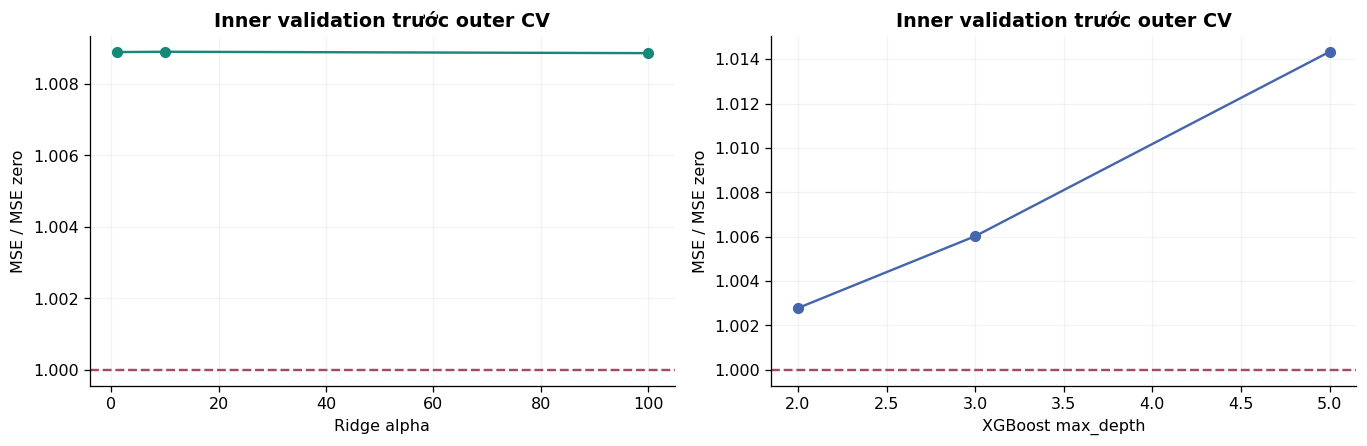

In [3]:
tuning, fig = study.tuning_chart()
display(tuning)
study.show(fig)
print('6 thử nghiệm inner split trước outer validation; không thay cấu hình baseline đã cố định.')

In [4]:
registry, run = study.train_tabular()
display(__import__('pandas').DataFrame([{k:v for k,v in m.items() if k in ['model','training_rows','fit_seconds','artifact_bytes','signal_approved']} for m in registry.values()]))

,model,training_rows,fit_seconds,artifact_bytes,signal_approved
0,ridge,67608,0.093866,2586,False
1,xgboost_d3,67608,0.624710,149686,False


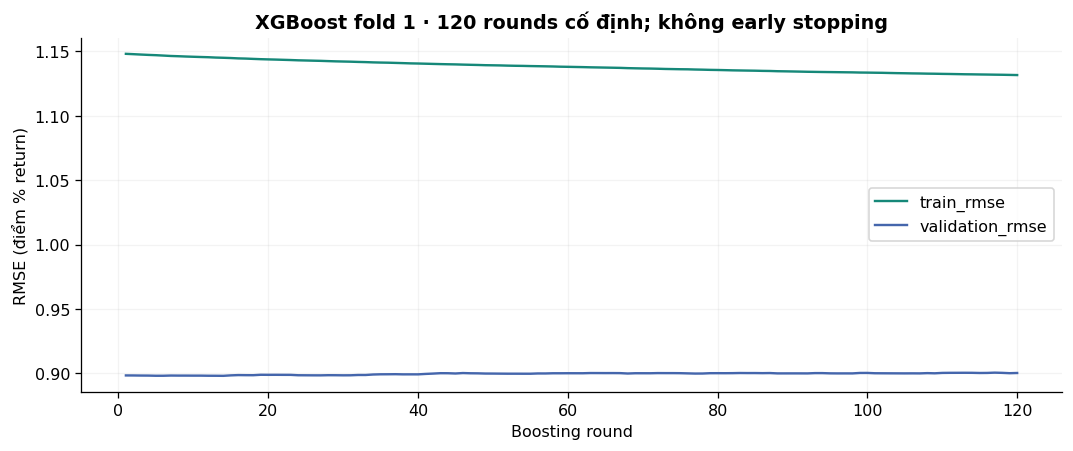

In [5]:
study.learning_charts()

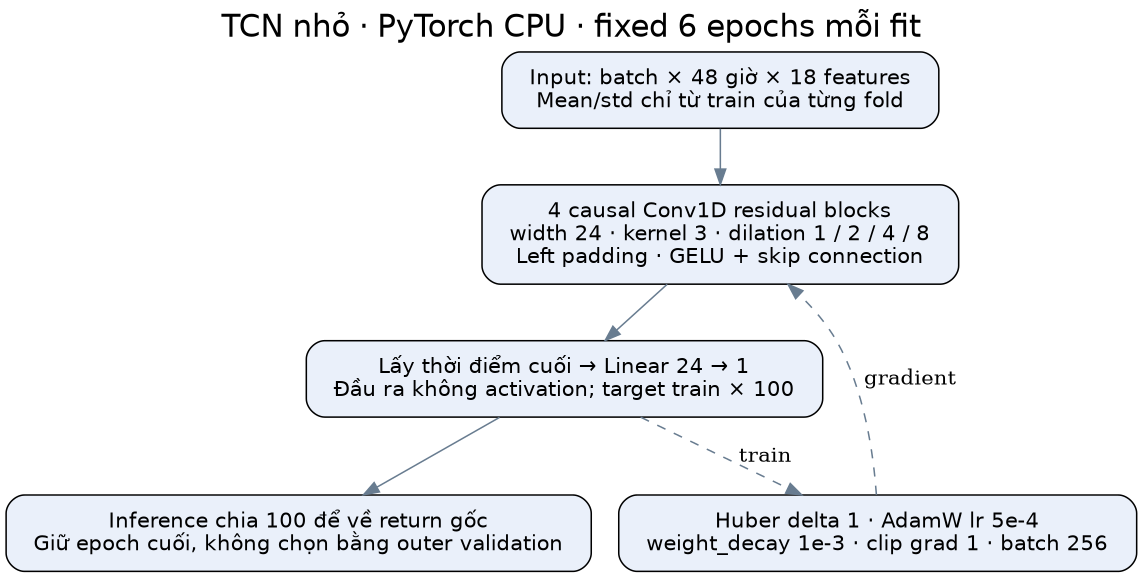

In [6]:
study.diagram('tcn')

In [7]:
history, fits = study.train_tcn()
display(fits)
display(history)

TCN 1 epoch 1/6: Huber=0.417506
TCN 1 epoch 2/6: Huber=0.410782
TCN 1 epoch 3/6: Huber=0.408887
TCN 1 epoch 4/6: Huber=0.407353
TCN 1 epoch 5/6: Huber=0.406280
TCN 1 epoch 6/6: Huber=0.405042
TCN 2 epoch 1/6: Huber=0.416115
TCN 2 epoch 2/6: Huber=0.409005
TCN 2 epoch 3/6: Huber=0.407636
TCN 2 epoch 4/6: Huber=0.406178
TCN 2 epoch 5/6: Huber=0.404785
TCN 2 epoch 6/6: Huber=0.403593
TCN 3 epoch 1/6: Huber=0.414737
TCN 3 epoch 2/6: Huber=0.408523
TCN 3 epoch 3/6: Huber=0.406412
TCN 3 epoch 4/6: Huber=0.405361
TCN 3 epoch 5/6: Huber=0.404094
TCN 3 epoch 6/6: Huber=0.402614
TCN final_refit epoch 1/6: Huber=0.414585
TCN final_refit epoch 2/6: Huber=0.407971
TCN final_refit epoch 3/6: Huber=0.406073
TCN final_refit epoch 4/6: Huber=0.404905
TCN final_refit epoch 5/6: Huber=0.403544
TCN final_refit epoch 6/6: Huber=0.402276


,fold,rows,windows,optimizer_steps
0,1,65700,65512,1536
1,2,66332,66144,1554
2,3,66964,66776,1566
3,final_refit,67608,67420,1584


,fold,epoch,train_huber,optimizer_steps_cumulative,training_windows,validation_mse
0,1,1,0.417506,256,65512,0.000078
1,1,2,0.410782,512,65512,0.000077
2,1,3,0.408887,768,65512,0.000078
3,1,4,0.407353,1024,65512,0.000077
4,1,5,0.406280,1280,65512,0.000076
5,1,6,0.405042,1536,65512,0.000078
6,2,1,0.416115,259,66144,0.000078
7,2,2,0.409005,518,66144,0.000080
8,2,3,0.407636,777,66144,0.000080
9,2,4,0.406178,1036,66144,0.000079


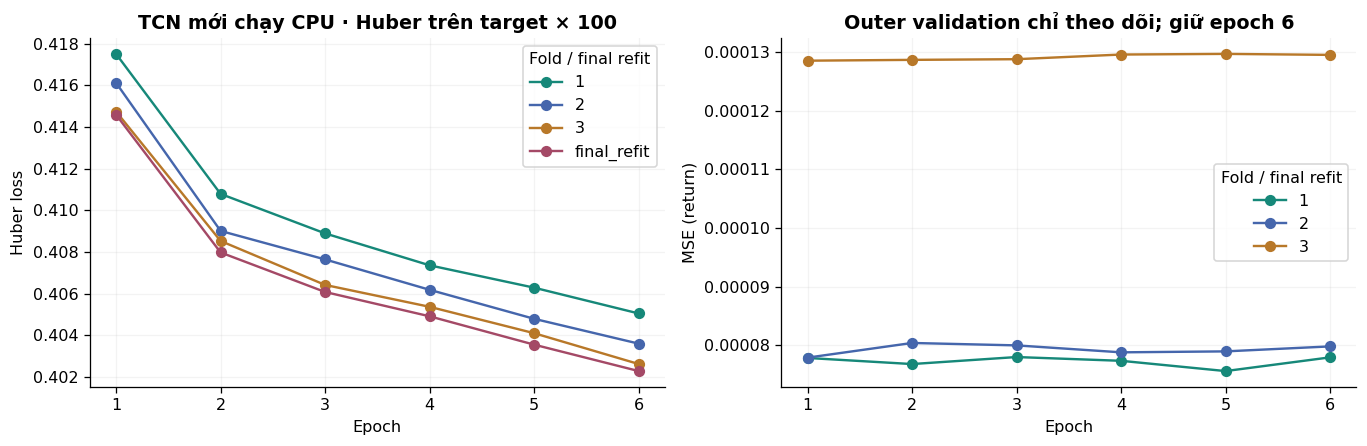

In [8]:
study.show(study.tcn_learning_chart())

Hệ số và importance chỉ mô tả final refit, không chứng minh quan hệ nhân quả.


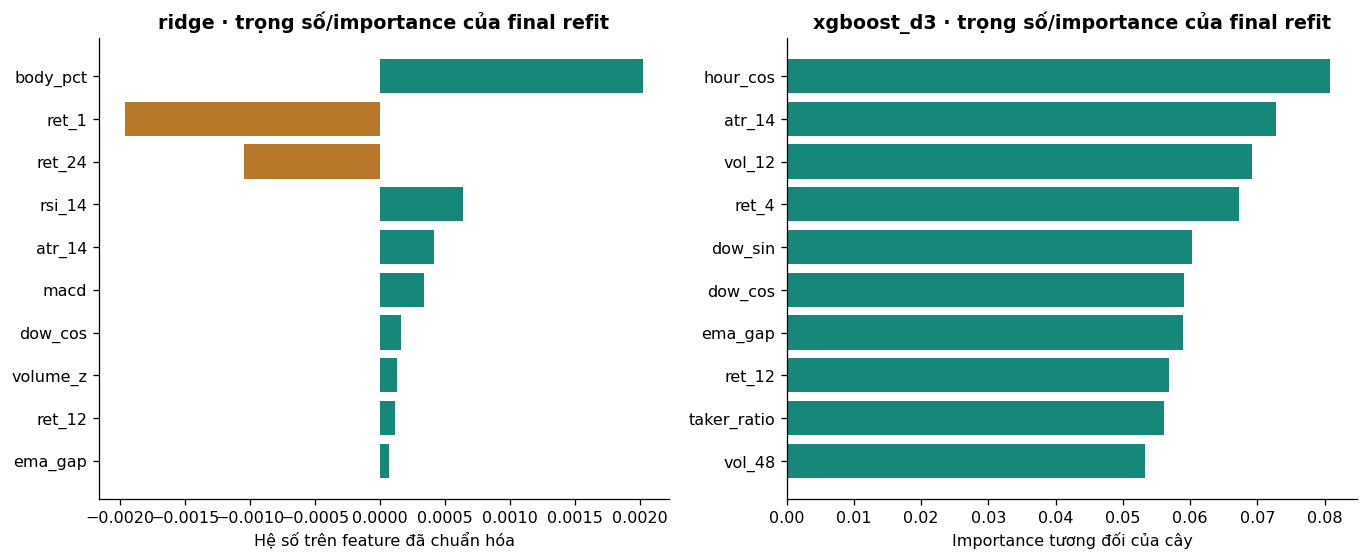

In [9]:
study.show(study.feature_chart())
print('Hệ số và importance chỉ mô tả final refit, không chứng minh quan hệ nhân quả.')